# Stage 7: Evaluation on the test sets

**Stage:** 7 (evaluation) · **Runs on:** Kaggle and locally (GPU helps if an expert is DistilBERT)

The only notebook that scores **test** data. Every choice (settings, experts, combiner, k) was
made earlier on validation data, so these scores are a fair estimate for new text.

| Section | Contents |
|---|---|
| A1 | In-dataset results: the 5 models on each dataset's test part |
| A2 | Cross-dataset matrices: trained on (rows) vs tested on (columns), per model |
| A3 | Final ensemble vs each expert; confusion matrix; speed; a check that the website loader gives the same answers |
| B | Regression on LIAR, and regression vs classification on the same LIAR statements |
| C | Clustering quality and cluster profiles on the test parts |
| D | Error analysis sample, top words, a LIME explanation |

| | |
|---|---|
| Input | everything from Stages 2, 4, 5 and 6 |
| Output | `results_*.csv` tables and `error_analysis_sample.csv` |

**On Kaggle:** attach the `misinfo_utils` utility script and add these notebooks as inputs (**Add Input → Your Work → Notebooks**): `02_split`, `04_features`, every Stage 5 notebook and `06_ensemble`.

In [1]:
# Setup: import the shared code. Works on Kaggle and locally.
import sys
from pathlib import Path

# Locally, misinfo_utils.py is in <project>/src/. On Kaggle it is an attached Utility Script,
# so this loop finds nothing and the import below still works.
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src" / "misinfo_utils.py").exists():
        sys.path.insert(0, str(folder / "src"))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import misinfo_utils as mu

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)
paths = mu.setup("07")

misinfo_utils | stage 07 | running on local
  read from : D:\misinfo-project\data\raw, D:\misinfo-project\outputs
  write to  : D:\misinfo-project\outputs\07_evaluation


In [2]:
import os, json, time
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

RUN_LIME = True

labels = {(ds, s): mu.load_split(ds, s)[["row_id", "label", "text"]] for ds in mu.DATASETS for s in ("val", "test")}
available = [m for m in mu.CLF_MODELS
             if all(mu.find_file(mu.pred_file(m, ds), required=False) for ds in mu.DATASETS)]
preds = {(m, ds): mu.load_predictions(m, ds) for m in available for ds in mu.DATASETS}
with open(mu.find_file(mu.FINAL_CONFIG)) as f:
    config = json.load(f)
experts = config["experts"]


def probs(model, trained_on, tested_on, split="test"):
    df = preds[(model, trained_on)]
    df = df[(df["tested_on"] == tested_on) & (df["split"] == split)].set_index("row_id")["prob_misleading"]
    return df.loc[labels[(tested_on, split)]["row_id"]].values


def y(ds, split="test"):
    return labels[(ds, split)]["label"].astype(int).values

print("Models:", available, "| experts:", experts, "| combiner:", config["combiner"])

Models: ['logreg', 'complementnb', 'linearsvm', 'lightgbm', 'distilbert'] | experts: {'liar': 'distilbert', 'welfake': 'distilbert', 'covid': 'distilbert', 'fakenewsnet': 'distilbert'} | combiner: blender


## A1. In-dataset results (test)

In [3]:
rows = []
for ds in mu.DATASETS:
    for m in available:
        rows.append({"dataset": ds, "model": mu.MODEL_NAMES[m], "expert": experts[ds] == m,
                     **mu.clf_scores(y(ds), probs(m, ds, ds))})
in_dataset = pd.DataFrame(rows)
mu.save_csv(in_dataset.round(4), "results_in_dataset.csv")

summary = in_dataset.pivot(index="model", columns="dataset", values="macro_F1")[mu.DATASETS]
summary["mean"] = summary.mean(axis=1)
print("Test macro F1 per model and dataset (* = that dataset's expert):")
marked = summary.round(3).astype(str)
for ds in mu.DATASETS:
    marked.loc[mu.MODEL_NAMES[experts[ds]], ds] += " *"
display(marked.sort_values("mean", ascending=False))
for ds in mu.DATASETS:
    print(f"\n{ds}"); display(in_dataset.query("dataset == @ds").drop(columns="dataset").set_index("model").round(4))

Saved      20 rows -> results_in_dataset.csv
Test macro F1 per model and dataset (* = that dataset's expert):


dataset,liar,welfake,covid,fakenewsnet,mean
model,,,,,
DistilBERT,0.635 *,0.98 *,0.958 *,0.788 *,0.84
Logistic Regression,0.627,0.956,0.931,0.776,0.822
LightGBM,0.638,0.953,0.911,0.775,0.82
Linear SVM,0.619,0.956,0.931,0.775,0.82
Complement NB,0.626,0.89,0.922,0.774,0.803



liar


,expert,accuracy,precision,recall,macro_F1,ROC_AUC
model,,,,,,
Logistic Regression,False,0.6361,0.6576,0.7175,0.6265,0.6773
Complement NB,False,0.6354,0.6573,0.7163,0.6259,0.6877
Linear SVM,False,0.6348,0.6467,0.7530,0.6194,0.6795
LightGBM,False,0.6511,0.6622,0.7577,0.6382,0.6903
DistilBERT,True,0.6479,0.6604,0.7518,0.6352,0.6942



welfake


,expert,accuracy,precision,recall,macro_F1,ROC_AUC
model,,,,,,
Logistic Regression,False,0.9563,0.9504,0.9538,0.9560,0.9890
Complement NB,False,0.8904,0.8700,0.8923,0.8897,0.9540
Linear SVM,False,0.9563,0.9497,0.9546,0.9560,0.9898
LightGBM,False,0.9537,0.9379,0.9619,0.9534,0.9896
DistilBERT,True,0.9800,0.9866,0.9692,0.9798,0.9981



covid


,expert,accuracy,precision,recall,macro_F1,ROC_AUC
model,,,,,,
Logistic Regression,False,0.9313,0.9386,0.9125,0.9309,0.9804
Complement NB,False,0.9222,0.9213,0.9111,0.9218,0.9799
Linear SVM,False,0.9313,0.9398,0.9111,0.9308,0.9805
LightGBM,False,0.9119,0.9044,0.9069,0.9115,0.9726
DistilBERT,True,0.9585,0.9686,0.9417,0.9583,0.9937



fakenewsnet


,expert,accuracy,precision,recall,macro_F1,ROC_AUC
model,,,,,,
Logistic Regression,False,0.7766,0.7781,0.7669,0.7765,0.8522
Complement NB,False,0.7746,0.7530,0.8099,0.7745,0.8612
Linear SVM,False,0.7746,0.7779,0.7617,0.7745,0.8531
LightGBM,False,0.7753,0.7835,0.7539,0.7751,0.8353
DistilBERT,True,0.7888,0.8284,0.7227,0.7876,0.8669


## A2. Cross-dataset matrices (test macro F1)

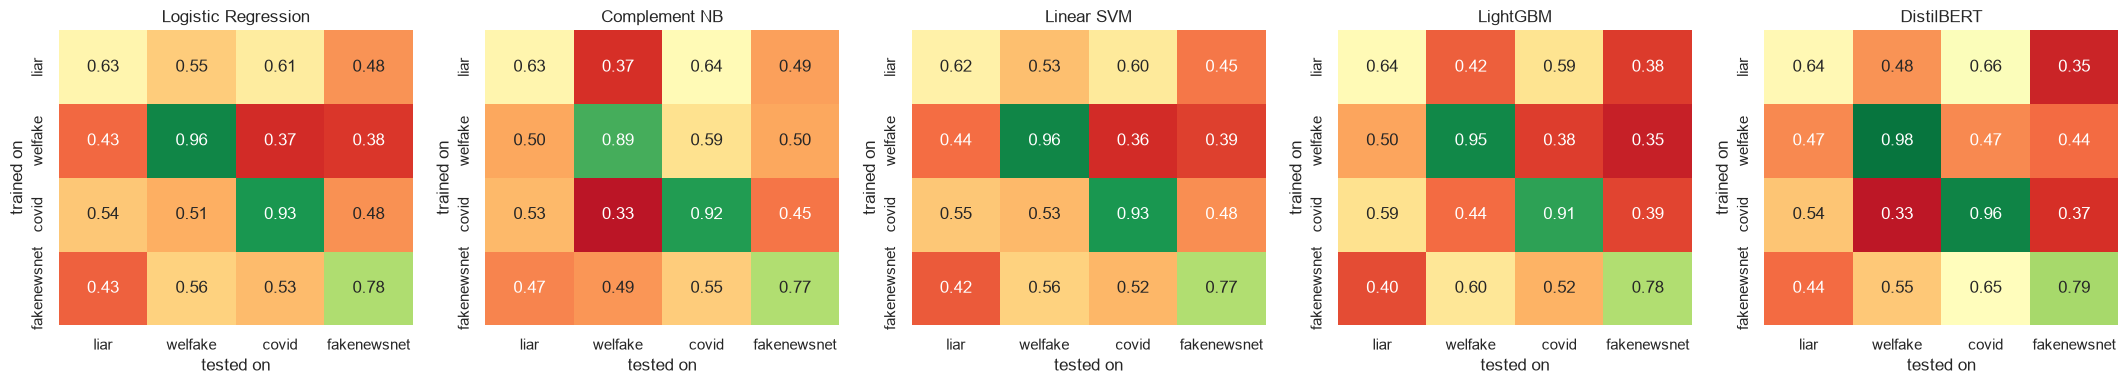

Saved      80 rows -> results_cross_dataset.csv


WindowsPath('D:/misinfo-project/outputs/07_evaluation/results_cross_dataset.csv')

In [4]:
cross_rows = []
fig, axes = plt.subplots(1, len(available), figsize=(4.3 * len(available), 4), squeeze=False)
for ax, m in zip(axes[0], available):
    mat = pd.DataFrame({tested: {trained: f1_score(y(tested), (probs(m, trained, tested) >= 0.5).astype(int), average="macro")
                                 for trained in mu.DATASETS} for tested in mu.DATASETS}).loc[mu.DATASETS, mu.DATASETS]
    cross_rows += [{"model": mu.MODEL_NAMES[m], "trained_on": tr, "tested_on": te, "macro_F1": mat.loc[tr, te]}
                   for tr in mu.DATASETS for te in mu.DATASETS]
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.3, vmax=1.0, cbar=False, ax=ax)
    ax.set_title(mu.MODEL_NAMES[m]); ax.set_xlabel("tested on"); ax.set_ylabel("trained on")
plt.tight_layout(); plt.show()
mu.save_csv(pd.DataFrame(cross_rows).round(4), "results_cross_dataset.csv")

**Reading it:** high values only on the diagonal mean a checkpoint only works on the kind of
text it was trained on. That is the reason for Stage 6's ensemble of dataset experts.

## A3. Final ensemble vs the experts (test)

Saved       5 rows -> results_final.csv


,liar,welfake,covid,fakenewsnet,mean over datasets
Final ensemble,0.4638,0.9737,0.7923,0.5257,0.6889
liar expert alone (DistilBERT),0.6352,0.4811,0.6570,0.3527,0.5315
welfake expert alone (DistilBERT),0.4716,0.9798,0.4707,0.4385,0.5902
covid expert alone (DistilBERT),0.5426,0.3331,0.9583,0.3700,0.5510
fakenewsnet expert alone (DistilBERT),0.4380,0.5463,0.6472,0.7876,0.6048


Final ensemble, all test rows pooled: {'accuracy': 0.7636, 'precision': 0.7832, 'recall': 0.7091, 'macro_F1': 0.7622, 'ROC_AUC': 0.8204}


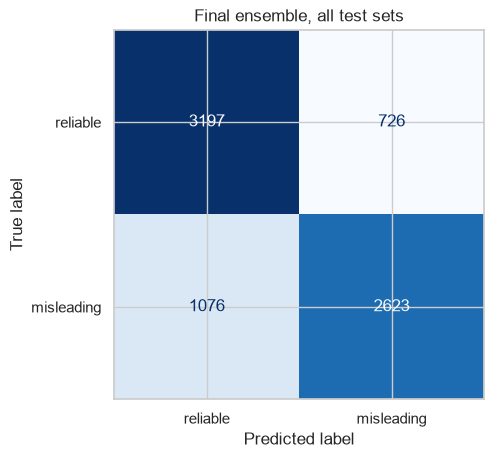

In [5]:
final = pd.read_csv(mu.find_file("pred__final.csv")).query("split == 'test'")

def final_probs(ds):
    return final[final["tested_on"] == ds].set_index("row_id")["prob_misleading"].loc[labels[(ds, "test")]["row_id"]].values

rows = {"Final ensemble": {ds: f1_score(y(ds), (final_probs(ds) >= 0.5).astype(int), average="macro") for ds in mu.DATASETS}}
for e in mu.DATASETS:
    rows[f"{e} expert alone ({mu.MODEL_NAMES[experts[e]]})"] = {
        ds: f1_score(y(ds), (probs(experts[e], e, ds) >= 0.5).astype(int), average="macro") for ds in mu.DATASETS}
final_table = pd.DataFrame(rows).T[mu.DATASETS]
final_table["mean over datasets"] = final_table.mean(axis=1)
mu.save_csv(final_table.round(4).reset_index(names="system"), "results_final.csv")
display(final_table.round(4))

y_all = np.concatenate([y(ds) for ds in mu.DATASETS])
p_all = np.concatenate([final_probs(ds) for ds in mu.DATASETS])
print("Final ensemble, all test rows pooled:", {k: round(v, 4) for k, v in mu.clf_scores(y_all, p_all).items()})
ConfusionMatrixDisplay(confusion_matrix(y_all, (p_all >= 0.5).astype(int)),
                       display_labels=["reliable", "misleading"]).plot(cmap="Blues", colorbar=False)
plt.title("Final ensemble, all test sets"); plt.show()

In [6]:
# The website's loader (mu.FinalModel) must give the same answers as the saved predictions.
fm = mu.FinalModel()
sample = pd.concat([labels[(ds, "test")].head(25).assign(ds=ds) for ds in mu.DATASETS])
t0 = time.time()
p_loader = fm.predict_proba(sample["text"].tolist())
ms_per_text = 1000 * (time.time() - t0) / len(sample)
p_saved = np.concatenate([final_probs(ds)[:25] for ds in mu.DATASETS])
print(f"Speed: {ms_per_text:.1f} ms per text on this machine ({mu.bert_device() if 'distilbert' in experts.values() else 'cpu'})")
print(f"Largest difference between loader and saved predictions: {np.abs(p_loader - p_saved).max():.6f}")

OSError: [WinError 127] The specified procedure could not be found. Error loading "C:\Users\USER\anaconda3\envs\misinfo\Lib\site-packages\torch\lib\shm.dll" or one of its dependencies.

## B. Regression on LIAR (test)

The regression vs classification comparison uses the LIAR test statements without half-true.
A predicted score below 3 counts as "misleading" (3 is the midpoint between barely-true = 2 and
mostly-true = 4, since half-true is excluded).

In [ ]:
y_reg = mu.load_split("liar_reg", "test").set_index("row_id")["score"].astype(float)
reg_models = mu.REG_MODELS + ["average_reg"]
reg_pred = {m: mu.load_predictions(m, "liar").query("split == 'test'").set_index("row_id")["pred_score"].loc[y_reg.index]
            for m in reg_models}
with open(mu.find_file("reg_final.json")) as f:
    best_reg = json.load(f)["best"]

reg_table = pd.DataFrame({mu.MODEL_NAMES[m]: mu.reg_scores(y_reg, p) for m, p in reg_pred.items()}).T.round(3)
mu.save_csv(reg_table.reset_index(names="model"), "results_regression.csv")
display(reg_table)

p_best = reg_pred[best_reg]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(x=y_reg.astype(int).map(mu.SCORE_NAMES), y=p_best.values, order=[mu.SCORE_NAMES[i] for i in range(6)],
            ax=axes[0], color="#8DA0CB", showfliers=False)
axes[0].plot(range(6), range(6), "r--", label="perfect prediction"); axes[0].legend()
axes[0].set_title(f"{mu.MODEL_NAMES[best_reg]}: predicted vs true (test)"); axes[0].set_xlabel("true rating")
axes[1].hist(p_best.values - y_reg.values, bins=30, color="#66C2A5", edgecolor="white")
axes[1].axvline(0, color="black"); axes[1].set_title("Prediction errors (predicted - true)")
plt.tight_layout(); plt.show()

In [ ]:
liar_ids = labels[("liar", "test")]["row_id"]
compare = {f"Regression: {mu.MODEL_NAMES[best_reg]} (score < 3)":
           (reg_pred[best_reg].loc[liar_ids].values < 3).astype(int)}
for m in available:
    compare[f"Classification: {mu.MODEL_NAMES[m]}"] = (probs(m, "liar", "liar") >= 0.5).astype(int)
liar_compare = pd.DataFrame({name: {"accuracy": float(np.mean(p == y("liar"))),
                                    "macro_F1": f1_score(y("liar"), p, average="macro")}
                             for name, p in compare.items()}).T.round(4)
mu.save_csv(liar_compare.reset_index(names="system"), "results_liar_comparison.csv")
liar_compare

## C. Clustering (test)

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA

clu_rows = []
fig, axes = plt.subplots(1, len(mu.DATASETS), figsize=(4.5 * len(mu.DATASETS), 4), squeeze=False)
for ax, ds in zip(axes[0], mu.DATASETS):
    X = normalize(mu.load_dense(ds, "test")[:, :mu.load_builder(ds).n_svd])
    clusters = pd.read_csv(mu.find_file(f"clusters__{ds}.csv")).query("split == 'test'")
    clusters = clusters.set_index("row_id").loc[labels[(ds, "test")]["row_id"]]
    for method in ("kmeans", "gmm"):
        c = clusters[method].values
        ok = len(set(c)) > 1
        clu_rows.append({"dataset": ds, "method": "K-Means" if method == "kmeans" else "Gaussian Mixture",
                         "clusters": len(set(c)),
                         "silhouette (higher better)": silhouette_score(X, c) if ok else np.nan,
                         "Davies-Bouldin (lower better)": davies_bouldin_score(X, c) if ok else np.nan})
    xy = PCA(n_components=2, random_state=mu.SEED).fit_transform(X)
    ax.scatter(xy[:, 0], xy[:, 1], c=clusters["kmeans"].values, cmap="tab10", s=6)
    ax.set_title(f"{ds}: K-Means clusters (test, 2-D view)"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
clu_table = pd.DataFrame(clu_rows).round(4)
mu.save_csv(clu_table, "results_clustering.csv")
display(clu_table)

for ds in mu.DATASETS:
    clusters = pd.read_csv(mu.find_file(f"clusters__{ds}.csv")).query("split == 'test'").merge(labels[(ds, "test")], on="row_id")
    profile = clusters.groupby("kmeans").agg(rows=("label", "size"), pct_misleading=("label", lambda s: round(100 * s.mean(), 1)))
    print(f"{ds}: % misleading per K-Means cluster (test)"); display(profile.T)

## D. Error analysis, top words and an explanation

In [ ]:
err_rows = []
for ds in mu.DATASETS:
    df = labels[(ds, "test")].assign(prob_misleading=final_probs(ds))
    wrong = df[(df["prob_misleading"] >= 0.5).astype(int) != df["label"].astype(int)]
    err_rows.append(wrong.sample(n=min(5, len(wrong)), random_state=mu.SEED).assign(dataset=ds))
errors = pd.concat(err_rows)[["dataset", "row_id", "label", "prob_misleading", "text"]]
errors["text"] = errors["text"].str.slice(0, 300)
errors["reason"] = ""     # fill in by hand: sarcasm, very short, topic unseen, label debatable, ...
mu.save_csv(errors, "error_analysis_sample.csv")
errors.round(3)

In [ ]:
import joblib
for ds in mu.DATASETS:
    path = mu.find_file(mu.checkpoint_file("logreg", ds), required=False)
    if path is None:
        continue
    coef = joblib.load(path).coef_[0]
    vocab = mu.load_builder(ds).tfidf.get_feature_names_out()
    print(f"{ds:12s} towards MISLEADING: {', '.join(vocab[np.argsort(coef)[-10:][::-1]])}")
    print(f"{'':12s} towards RELIABLE  : {', '.join(vocab[np.argsort(coef)[:10]])}")

In [ ]:
if RUN_LIME:
    try:
        from lime.lime_text import LimeTextExplainer
        explainer = LimeTextExplainer(class_names=["reliable", "misleading"], random_state=mu.SEED)
        example = labels[("liar", "test")].iloc[0]
        def both_classes(texts):
            p = fm.predict_proba(texts)
            return np.column_stack([1 - p, p])

        exp = explainer.explain_instance(example["text"], both_classes, num_features=8, num_samples=300)
        print("Text:", example["text"])
        print("True label:", mu.LABEL_NAMES[int(example["label"])])
        print("Words that pushed the final model (+ = towards misleading):")
        for word, weight in exp.as_list():
            print(f"  {word:20s} {weight:+.3f}")
    except ImportError:
        print("LIME is not installed (pip install lime); skipped.")